In [1]:
import pandas as pd

df = pd.read_csv('/content/customer_support_tickets.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Dataset shape: (8469, 17)

Column names:
['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']


,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [2]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nTicket types:")
print(df['Ticket Type'].value_counts())

print("\nTicket priorities:")
print(df['Ticket Priority'].value_counts())

Column names:
['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']

Missing values in each column:
Ticket ID                          0
Customer Name                      0
Customer Email                     0
Customer Age                       0
Customer Gender                    0
Product Purchased                  0
Date of Purchase                   0
Ticket Type                        0
Ticket Subject                     0
Ticket Description                 0
Ticket Status                      0
Resolution                      5700
Ticket Priority                    0
Ticket Channel                     0
First Response Time             2819
Time to Resolution              5700
Customer Satisfaction Rating    5700


In [3]:
# Select the columns needed for the project
data = df[['Ticket Type', 'Ticket Priority',
           'Ticket Subject', 'Ticket Description']].copy()

# Remove rows with missing values
data = data.dropna()

# Combine ticket subject and description
data['Ticket Text'] = (
    data['Ticket Subject'].astype(str) + ' ' +
    data['Ticket Description'].astype(str)
)

# Remove empty ticket text
data = data[data['Ticket Text'].str.strip() != '']

print("Data prepared successfully!")
print("Rows and columns:", data.shape)

data[['Ticket Text', 'Ticket Type', 'Ticket Priority']].head()

Data prepared successfully!
Rows and columns: (8469, 5)


,Ticket Text,Ticket Type,Ticket Priority
0,Product setup I'm having an issue with the {pr...,Technical issue,Critical
1,Peripheral compatibility I'm having an issue w...,Technical issue,Critical
2,Network problem I'm facing a problem with my {...,Technical issue,Low
3,Account access I'm having an issue with the {p...,Billing inquiry,Low
4,Data loss I'm having an issue with the {produc...,Billing inquiry,Low


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert ticket text into numerical features
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=5000
)

X = tfidf.fit_transform(data['Ticket Text'])

print("TF-IDF conversion completed!")
print("Number of tickets:", X.shape[0])
print("Number of text features:", X.shape[1])

TF-IDF conversion completed!
Number of tickets: 8469
Number of text features: 5000


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Input: ticket text features
# Output: ticket categories
y = data['Ticket Type']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predict ticket categories
y_pred = model.predict(X_test)

# Evaluate the model
print("Ticket Type Classification Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Ticket Type Classification Results
Accuracy: 20.48 %

Classification Report:
                      precision    recall  f1-score   support

     Billing inquiry       0.19      0.17      0.18       327
Cancellation request       0.20      0.21      0.20       339
     Product inquiry       0.22      0.22      0.22       328
      Refund request       0.21      0.21      0.21       351
     Technical issue       0.21      0.22      0.21       349

            accuracy                           0.20      1694
           macro avg       0.20      0.20      0.20      1694
        weighted avg       0.20      0.20      0.20      1694



In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Prepare ticket priority labels
data['Priority'] = data['Ticket Priority'].astype(str).str.strip().str.title()

# Combine Critical and High into High
data['Priority'] = data['Priority'].replace({
    'Critical': 'High'
})

# Prepare text features and target labels
X_priority = tfidf.transform(data['Ticket Text'])
y_priority = data['Priority']

# Split the data
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_priority, y_priority,
    test_size=0.2,
    random_state=42,
    stratify=y_priority
)

# Train the priority model
priority_model = LogisticRegression(max_iter=1000)
priority_model.fit(X_train_p, y_train_p)

# Make predictions
priority_pred = priority_model.predict(X_test_p)

# Evaluate the model
print("Ticket Priority Prediction Results")
print("Accuracy:", round(
    accuracy_score(y_test_p, priority_pred) * 100, 2
), "%")

print("\nClassification Report:")
print(classification_report(
    y_test_p, priority_pred, zero_division=0
))

Ticket Priority Prediction Results
Accuracy: 47.82 %

Classification Report:
              precision    recall  f1-score   support

        High       0.50      0.91      0.65       843
         Low       0.25      0.04      0.06       413
      Medium       0.28      0.06      0.10       438

    accuracy                           0.48      1694
   macro avg       0.34      0.34      0.27      1694
weighted avg       0.38      0.48      0.36      1694



In [7]:
# Test with a new customer support ticket
new_ticket = [
    "I was charged twice for my payment and need a refund"
]

# Convert the text using the same TF-IDF vectorizer
new_ticket_tfidf = tfidf.transform(new_ticket)

# Predict ticket type
predicted_type = model.predict(new_ticket_tfidf)

# Predict ticket priority
predicted_priority = priority_model.predict(new_ticket_tfidf)

print("Customer Support Ticket:")
print(new_ticket[0])

print("\nPredicted Ticket Type:", predicted_type[0])
print("Predicted Ticket Priority:", predicted_priority[0])

Customer Support Ticket:
I was charged twice for my payment and need a refund

Predicted Ticket Type: Refund request
Predicted Ticket Priority: High


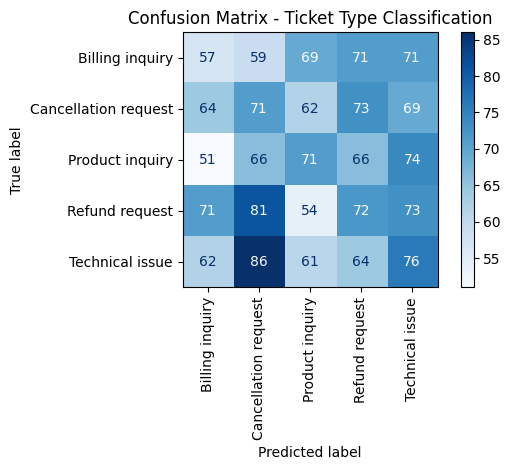

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create confusion matrix for ticket type classification
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation='vertical',
    cmap='Blues'
)

plt.title("Confusion Matrix - Ticket Type Classification")
plt.tight_layout()
plt.show()